# 03 · Optimización de portafolios con restricción ESG

**Idea:** en lugar de la frontera riesgo–rendimiento de Markowitz, construir una frontera **riesgo–ESG**: la mínima volatilidad alcanzable para cada score ESG objetivo. Matemáticamente, el score del portafolio $ESG_p=\sum_i w_i\,ESG_i$ es lineal en los pesos, igual que el rendimiento esperado.

$$\min_{w}\; w^\top\Sigma w \quad \text{s.a.}\quad \mathbf 1^\top w = 1,\;\; 0\le w_i\le 1,\;\; w^\top s \ge s^*$$

- $\Sigma$: covarianza de rendimientos diarios; volatilidad anualizada $\sigma_p=\sqrt{252\,w^\top\Sigma w}$.
- $s$: vector de scores ESG (0–10); $s^*$: score mínimo exigido.

Datos: universo anonimizado de 10 emisoras mexicanas, precios diarios abr-2012 a abr-2013, score ESG ilustrativo. Ejercicio educativo, no recomendación de inversión.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esg_workshop.plotting import use_style, SERIES, COOL, WARM, MUTED, INK_2

use_style()
pd.set_option("display.precision", 3)
from esg_workshop import esg_data as ed, portfolio as pf

In [2]:
prices = pf.load_sample_prices()
returns = pf.daily_returns(prices)
esg = ed.load_sample_universe().set_index("ticker").loc[returns.columns, "esg_score"]
print(f"{len(returns)} días, {returns.shape[1]} activos")
pd.DataFrame({"vol_anual": returns.std() * np.sqrt(252), "ret_anual": returns.mean() * 252, "esg_score": esg})

262 días, 10 activos


,vol_anual,ret_anual,esg_score
Stock1,0.236,0.180,7.5
Stock2,0.268,0.612,5.5
Stock3,0.394,-0.043,9.0
Stock4,0.246,0.317,6.0
Stock5,0.408,0.690,7.0
Stock6,0.490,0.457,6.0
Stock7,0.292,0.437,5.0
Stock8,0.233,0.371,4.0
Stock9,0.383,0.576,0.0
Stock10,1.306,0.034,8.0


## 1. Portafolio de mínima varianza (MVP) sin restricción ESG

In [3]:
mvp = pf.min_variance(returns)
pd.Series(pf.portfolio_stats(mvp, returns, esg))

volatility         0.125
expected_return    0.349
esg_score          5.860
n_assets           9.000
max_weight         0.275
dtype: float64

## 2. MVP con score ESG mínimo de 7

In [4]:
esg_mvp = pf.min_variance(returns, esg, min_esg=7)
comparison = pd.DataFrame({"MVP": pf.portfolio_stats(mvp, returns, esg), "MVP con ESG ≥ 7": pf.portfolio_stats(esg_mvp, returns, esg)})
comparison

,MVP,MVP con ESG ≥ 7
volatility,0.125,0.140
expected_return,0.349,0.276
esg_score,5.860,7.000
n_assets,9.000,8.000
max_weight,0.275,0.374


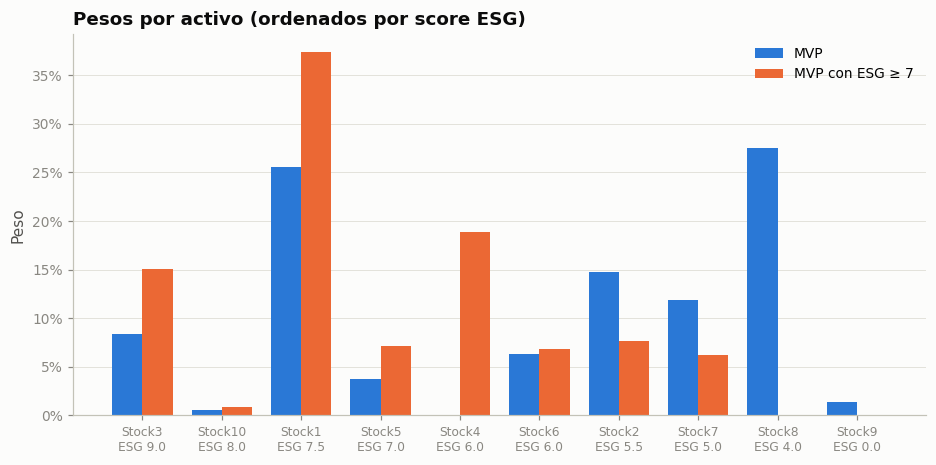

In [5]:
w = pd.DataFrame({"MVP": mvp, "MVP con ESG ≥ 7": esg_mvp}).loc[esg.sort_values(ascending=False).index]
x = np.arange(len(w)); width = 0.38
fig, ax = plt.subplots()
ax.bar(x - width / 2, w["MVP"], width, color=SERIES[0], label="MVP")
ax.bar(x + width / 2, w["MVP con ESG ≥ 7"], width, color=SERIES[1], label="MVP con ESG ≥ 7")
ax.set_xticks(x, [f"{t}\nESG {esg[t]:.1f}" for t in w.index], fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Pesos por activo (ordenados por score ESG)", ylabel="Peso"); ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
plt.show()

## 3. Frontera eficiente riesgo–ESG
Para cada score objetivo entre el del MVP y el máximo del universo se resuelve el problema con la restricción ESG como igualdad.

In [6]:
frontier = pf.esg_frontier(returns, esg, n_points=25)
frontier[["target_esg", "volatility", "expected_return", "n_assets", "max_weight"]].iloc[::4]

,target_esg,volatility,expected_return,n_assets,max_weight
0,5.860,0.125,0.349,9,0.276
4,6.383,0.128,0.330,9,0.294
8,6.906,0.137,0.287,8,0.357
12,7.430,0.160,0.222,8,0.450
16,7.953,0.199,0.148,5,0.518
20,8.477,0.273,0.034,3,0.648
24,9.000,0.394,-0.043,1,1.000


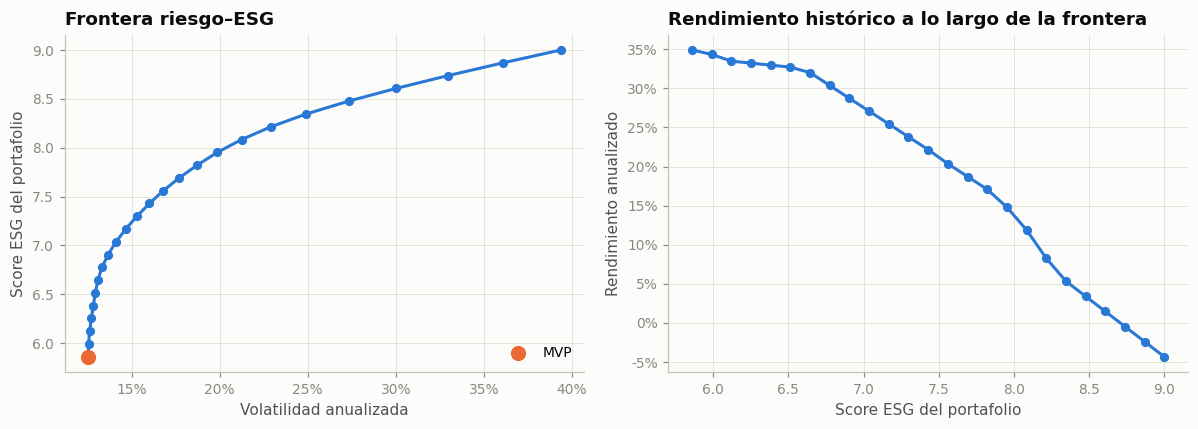

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(frontier.volatility, frontier.esg_score, color=COOL, marker="o")
axes[0].scatter(*[pf.portfolio_stats(mvp, returns, esg)[k] for k in ("volatility", "esg_score")], s=80, color=SERIES[1], zorder=3, label="MVP")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set(title="Frontera riesgo–ESG", xlabel="Volatilidad anualizada", ylabel="Score ESG del portafolio"); axes[0].legend(loc="lower right")
axes[1].plot(frontier.esg_score, frontier.expected_return, color=COOL, marker="o")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set(title="Rendimiento histórico a lo largo de la frontera", xlabel="Score ESG del portafolio", ylabel="Rendimiento anualizado")
plt.tight_layout(); plt.show()

## Conclusiones y limitaciones
- Exigir un score ESG más alto **concentra** el portafolio (menos activos, peso máximo mayor) y eleva la volatilidad: es el costo de diversificación de la restricción.
- En esta muestra el rendimiento histórico cae al subir el score, pero **no es un resultado general**: depende del universo, del periodo y del régimen de mercado.
- Supuestos: covarianza muestral estable, un solo score agregado (sin pilares E/S/G), sin costos de transacción. Extensiones: covarianza con *shrinkage*, restricciones por pilar o por intensidad de carbono, *tracking error* contra un índice.